In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from datasets import load_dataset
from matplotlib.colors import LogNorm
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

REPO_ROOT = Path("/lfs/skampere2/0/animjha/CleanSlate")
SCRIPTS_DIR = REPO_ROOT / "scripts" / "dataset_search"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))
from igm_lib import word_spans

/lfs/skampere2/0/animjha/CleanSlate/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
OLMO_MEMORIZATION_DATASET = "unlearning-cleanslate/verif-olmo-3-1125-32b-w100-s10"
QWEN3_CODER_MEMORIZATION_DATASET = "unlearning-cleanslate/verif-qwen3-coder-next-w100-s10"
GEMMA_MEMORIZATION_DATASET = "unlearning-cleanslate/verif-gemma-3-12b-pt-w100-s10"
LLAMA_MEMORIZATION_DATASET = "unlearning-cleanslate/verif-llama-3.1-8b-w100-s10"
SPAN_COVERAGE_ROOT = REPO_ROOT / "results" / "igm_full" / "songs"

In [3]:
MEM_DATASETS = {
    "OLMo-3 32B":  OLMO_MEMORIZATION_DATASET,
    "Qwen3 Coder": QWEN3_CODER_MEMORIZATION_DATASET,
    "Gemma-3 12B": GEMMA_MEMORIZATION_DATASET,
    "Llama-3.1 8B": LLAMA_MEMORIZATION_DATASET
}
MEM_DFS = {
    label: load_dataset(repo, "default")["train"].to_polars()
    for label, repo in MEM_DATASETS.items()
}
df = MEM_DFS["OLMo-3 32B"]  # kept as alias for the inspection cells below
print({label: d.height for label, d in MEM_DFS.items()})

{'OLMo-3 32B': 4663, 'Qwen3 Coder': 4663, 'Gemma-3 12B': 4663, 'Llama-3.1 8B': 4663}


In [4]:
def per_word_max_pz(text: str, char_to_max_pz) -> np.ndarray:
    """Per word: max p_z over all windows touching any of the word's characters.

    `char_to_max_pz[c]` is the precomputed max p_z over windows covering char `c`
    in the eval dataset. For each word `(ws, we)` we take `max(char_to_max_pz[ws:we])`,
    which equals `max(p_z over windows whose [start_char, end_char) overlaps the word)`.
    """
    arr = np.asarray(char_to_max_pz, dtype=np.float64)
    return np.array([
        arr[ws:we].max() if we > ws and we <= len(arr) else 0.0
        for ws, we in word_spans(text)
    ])

In [5]:
PZ_VMIN = 1e-3
_VIRIDIS_W = plt.get_cmap("viridis").copy()
_VIRIDIS_W.set_bad("white")


def draw_mem_strip(ax, max_pz_per_word, *, label="max $p_z$", vmin=PZ_VMIN, vmax=1.0):
    """Single-row viridis log strip of per-word max p_z; white where pz < vmin.

    `label` is shown as the y-tick (e.g. the model name).
    """
    n = len(max_pz_per_word)
    row = np.where(max_pz_per_word >= vmin, max_pz_per_word.astype(float), np.nan)
    im = ax.imshow(
        row[None, :], aspect="auto", cmap=_VIRIDIS_W,
        norm=LogNorm(vmin=vmin, vmax=vmax),
        extent=(0, n, 1, 0), interpolation="nearest",
    )
    ax.set_yticks([0.5])
    ax.set_yticklabels([label], fontsize=8)
    ax.tick_params(axis="x", labelbottom=False, length=0)
    for s in ("top", "right", "left", "bottom"):
        ax.spines[s].set_visible(False)
    return im


def draw_occ_strips(ax, occ_counts_by_n, *, n_words=None):
    """Per-N viridis log strips: one row per N, color = Σ occurrence count; white = 0."""
    ns = sorted(occ_counts_by_n.keys())
    mat = np.stack([occ_counts_by_n[n].astype(float) for n in ns])
    masked = np.where(mat == 0, np.nan, mat)
    finite = mat[mat > 0]
    vmax = int(finite.max()) if finite.size else 2
    n_words = n_words or mat.shape[1]
    im = ax.imshow(
        masked, aspect="auto", cmap=_VIRIDIS_W,
        norm=LogNorm(vmin=1, vmax=max(vmax, 2)),
        extent=(0, n_words, len(ns), 0), interpolation="nearest",
    )
    ax.set_yticks([i + 0.5 for i in range(len(ns))])
    ax.set_yticklabels([f"N={n}" for n in ns], fontsize=8)
    ax.set_xlabel("word index", fontsize=9)
    ax.tick_params(axis="x", labelsize=8)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    return im, ns

In [6]:
INCLUDED_NS = (5, 7, 10, 15, 25)  # N values to show in the coverage block


def load_song_data(song_id: str, mem_dfs: dict[str, pl.DataFrame]) -> dict:
    """Bundle reference text, igm coverage arrays, and per-model per-word max p_z.

    `mem_dfs` maps model label → polars frame loaded from a *_MEMORIZATION_DATASET.
    Returns `pz_per_model: {label: np.ndarray of length n_words}` plus shared text /
    coverage / meta. Coverage block is filtered to `INCLUDED_NS` (N values present
    on disk but not in the tuple are dropped).
    """
    song_dir = SPAN_COVERAGE_ROOT / song_id
    text = (song_dir / "reference_text.txt").read_text()
    occ = np.load(song_dir / "occ_counts.npz")
    occ_counts_by_n = {
        int(k.lstrip("N")): occ[k] for k in occ.files
        if int(k.lstrip("N")) in INCLUDED_NS
    }
    meta = json.loads((song_dir / "meta.json").read_text())

    pz_per_model: dict[str, np.ndarray] = {}
    for label, mem_df in mem_dfs.items():
        row = mem_df.filter(pl.col("song_id") == song_id)
        if row.height == 0:
            raise KeyError(f"song_id {song_id} not in mem dataset for {label!r}")
        pz_per_model[label] = per_word_max_pz(text, row.row(0, named=True)["char_to_max_pz"])

    return {
        "song_id": song_id,
        "text": text,
        "meta": meta,
        "occ_counts_by_n": occ_counts_by_n,
        "pz_per_model": pz_per_model,
    }


def _song_title(meta: dict, song_id: str) -> str:
    parts = []
    if meta.get("song_title"):
        parts.append(str(meta["song_title"]))
    if meta.get("content_creators"):
        parts.append(f"— {meta['content_creators']}")
    if meta.get("content_year"):
        parts.append(f"({meta['content_year']})")
    return " ".join(parts) if parts else song_id

In [7]:
def render_song_panel(fig, subplot_spec, song_id, mem_dfs, *, title=None):
    """Render one song's multi-model two-panel cell into `subplot_spec`.

    Top sub-rows: one per-word memorization strip per model in `mem_dfs`
    (rows ordered by dict insertion, label = dict key).
    Bottom sub-row: per-N corpus n-gram coverage strips.
    All strips share the word-index x-axis. One shared p_z colorbar across the mem
    rows; one Σ-occurrence colorbar for the coverage block. Returns
    (ax_mems: list, ax_occ).
    """
    data = load_song_data(song_id, mem_dfs)
    n_words = len(next(iter(data["pz_per_model"].values())))
    n_models = len(data["pz_per_model"])
    n_n = len(data["occ_counts_by_n"])

    inner = GridSpecFromSubplotSpec(
        n_models + 1, 2,
        subplot_spec=subplot_spec,
        height_ratios=[1] * n_models + [n_n],
        width_ratios=[60, 1],
        hspace=0.06, wspace=0.025,
    )

    ax_mems = []
    im_mem = None
    for i, (label, pz) in enumerate(data["pz_per_model"].items()):
        ax = fig.add_subplot(inner[i, 0], sharex=ax_mems[0] if ax_mems else None)
        im_mem = draw_mem_strip(ax, pz, label=label)
        ax_mems.append(ax)
    ax_occ = fig.add_subplot(inner[n_models, 0], sharex=ax_mems[0])
    im_occ, _ = draw_occ_strips(ax_occ, data["occ_counts_by_n"], n_words=n_words)

    cax_mem = fig.add_subplot(inner[0:n_models, 1])
    cax_occ = fig.add_subplot(inner[n_models, 1])
    cb_mem = fig.colorbar(im_mem, cax=cax_mem)
    cb_mem.ax.tick_params(labelsize=7)
    cb_mem.set_label(r"$p_z$", fontsize=8)
    cb_occ = fig.colorbar(im_occ, cax=cax_occ)
    cb_occ.ax.tick_params(labelsize=7)
    cb_occ.set_label("Σ occ", fontsize=8)

    ax_mems[0].set_title(
        title or _song_title(data["meta"], song_id),
        fontsize=10, loc="center", pad=4,
    )
    return ax_mems, ax_occ

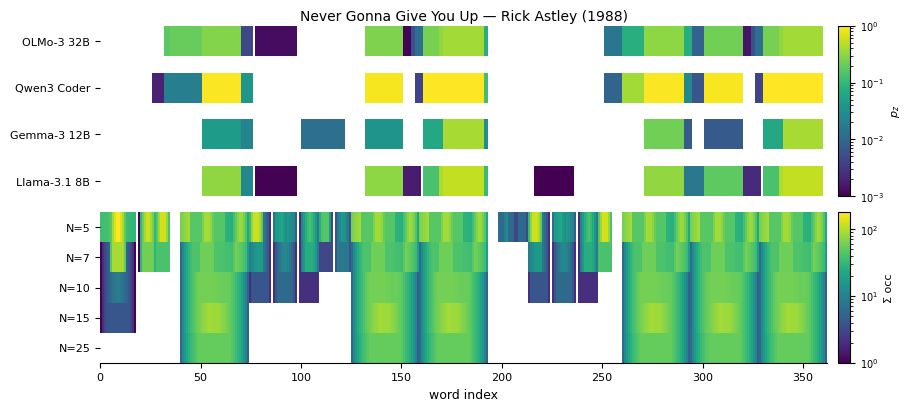

In [46]:
NEVER_GONNA_ID = "b9bb555ab4913dfeaafb409555e8f543f5180fc6"

fig = plt.figure(figsize=(9, 4.0), constrained_layout=True)
gs = GridSpec(1, 1, figure=fig)
render_song_panel(fig, gs[0, 0], NEVER_GONNA_ID, MEM_DFS)
plt.show()

In [36]:
from tqdm.auto import tqdm

N_BINS = 100  # normalize to 0–100% of the work
_POP_REDUCERS = {"median": np.nanmedian, "mean": np.nanmean, "max": np.nanmax}


def _project_to_bins(per_word: np.ndarray, n_bins: int, *, op: str) -> np.ndarray:
    """Resample a per-word array onto n_bins position bins (0–100%).

    Bin b owns words[int(b*n/N) : int((b+1)*n/N)] — proper position-interval
    slicing so every bin gets ≥1 word (block downsample when n_words ≥ n_bins,
    nearest-neighbor upsample when n_words < n_bins). No NaN holes.

    `op="max"` for intensity signals (p_z), `op="sum"` for additive counts
    (Σ-span occurrences per word), `op="mean"` for averages.
    """
    n = len(per_word)
    out = np.empty(n_bins, dtype=np.float64)
    for b in range(n_bins):
        lo = int(b * n / n_bins)
        hi = int((b + 1) * n / n_bins)
        if hi <= lo:                # only when n_words < n_bins
            hi = lo + 1
        sl = per_word[lo:min(hi, n)]
        if op == "sum":
            out[b] = sl.sum()
        elif op == "max":
            out[b] = sl.max()
        else:
            out[b] = sl.mean()
    return out


def compute_population_panels(
    mem_dfs: dict[str, pl.DataFrame],
    ids: set[str] | list[str],
    *,
    n_bins: int = N_BINS,
    agg: str = "median",
    min_words: int = 50,
) -> dict:
    """Aggregate per-word mem and per-N coverage across `ids` into n_bins position bins.

    Within a work: bin b spans the word interval [b/n_bins, (b+1)/n_bins) of the
    work. Per-bin reduction is `max` for p_z (intensity) and `sum` for Σ-occ
    (additive count of spans covering the words in the bin). Across works:
    reduction is `agg ∈ {median, mean, max}`. Color is rendered later via
    LogNorm — the aggregated arrays hold raw p_z / raw Σ-occ values.
    """
    if agg not in _POP_REDUCERS:
        raise ValueError(f"agg must be one of {list(_POP_REDUCERS)}")
    reducer = _POP_REDUCERS[agg]

    on_disk = {p.name for p in SPAN_COVERAGE_ROOT.iterdir()
               if p.is_dir() and (p / "occ_counts.npz").exists()
               and (p / "reference_text.txt").exists()}
    candidate = set(ids) & on_disk
    for mdf in mem_dfs.values():
        candidate &= set(mdf["song_id"].to_list())

    pz_per_model: dict[str, list[np.ndarray]] = {label: [] for label in mem_dfs}
    occ_per_n: dict[int, list[np.ndarray]] = {n: [] for n in INCLUDED_NS}
    kept: list[str] = []

    for sid in tqdm(sorted(candidate), desc=f"binning ({agg})"):
        sd = SPAN_COVERAGE_ROOT / sid
        text = (sd / "reference_text.txt").read_text()
        n_words = len(word_spans(text))
        if n_words < min_words:
            continue

        occ_npz = np.load(sd / "occ_counts.npz")
        occ_arrays_by_n: dict[int, np.ndarray] = {}
        skip = False
        for n in INCLUDED_NS:
            key = f"N{n}"
            if key not in occ_npz.files:
                skip = True
                break
            arr = occ_npz[key].astype(float)
            if len(arr) != n_words:
                skip = True
                break
            occ_arrays_by_n[n] = _project_to_bins(arr, n_bins, op="sum")
        if skip:
            continue

        pz_binned: dict[str, np.ndarray] = {}
        for label, mdf in mem_dfs.items():
            row = mdf.filter(pl.col("song_id") == sid)
            if row.height == 0:
                skip = True
                break
            c2p = row.row(0, named=True)["char_to_max_pz"]
            pz = per_word_max_pz(text, c2p)
            if len(pz) != n_words:
                skip = True
                break
            pz_binned[label] = _project_to_bins(pz, n_bins, op="max")
        if skip:
            continue

        for label, arr in pz_binned.items():
            pz_per_model[label].append(arr)
        for n, arr in occ_arrays_by_n.items():
            occ_per_n[n].append(arr)
        kept.append(sid)

    pz_out = {label: reducer(np.stack(v), axis=0) if v else np.full(n_bins, np.nan)
              for label, v in pz_per_model.items()}
    occ_out = {n: reducer(np.stack(v), axis=0) if v else np.full(n_bins, np.nan)
               for n, v in occ_per_n.items()}
    return {
        "pz_per_model": pz_out,
        "occ_counts_by_n": occ_out,
        "n_items": len(kept),
        "song_ids": kept,
        "agg": agg,
    }

In [37]:
def render_population_panel(fig, subplot_spec, pop, *, title=None):
    """Population analog of render_song_panel.

    Stacks per-model memorization strips on top, per-N coverage strips below,
    all 1×N_BINS where the x-axis represents normalized position (0–100%) in
    the work. Reuses draw_mem_strip / draw_occ_strips for identical color
    semantics (viridis log, white-below-threshold, shared colorbars).
    """
    pz = pop["pz_per_model"]
    occ = pop["occ_counts_by_n"]
    n_models = len(pz)
    n_n = len(occ)
    n_bins = len(next(iter(pz.values())))

    inner = GridSpecFromSubplotSpec(
        n_models + 1, 2,
        subplot_spec=subplot_spec,
        height_ratios=[1] * n_models + [n_n],
        width_ratios=[60, 1],
        hspace=0.06, wspace=0.025,
    )

    ax_mems = []
    im_mem = None
    for i, (label, arr) in enumerate(pz.items()):
        ax = fig.add_subplot(inner[i, 0], sharex=ax_mems[0] if ax_mems else None)
        im_mem = draw_mem_strip(ax, arr, label=label)
        ax_mems.append(ax)
    ax_occ = fig.add_subplot(inner[n_models, 0], sharex=ax_mems[0])
    im_occ, _ = draw_occ_strips(ax_occ, occ, n_words=n_bins)
    ax_occ.set_xlabel("position in work (%)", fontsize=9)

    cax_mem = fig.add_subplot(inner[0:n_models, 1])
    cax_occ = fig.add_subplot(inner[n_models, 1])
    cb_mem = fig.colorbar(im_mem, cax=cax_mem)
    cb_mem.ax.tick_params(labelsize=7)
    cb_mem.set_label(r"$p_z$", fontsize=8)
    cb_occ = fig.colorbar(im_occ, cax=cax_occ)
    cb_occ.ax.tick_params(labelsize=7)
    cb_occ.set_label("Σ occ", fontsize=8)

    ax_mems[0].set_title(
        title or f"Population aggregate ({pop['agg']}) over n={pop['n_items']}",
        fontsize=10, loc="center", pad=4,
    )
    return ax_mems, ax_occ

In [43]:
import json

dep = load_dataset("unlearning-cleanslate/cleanslate_dataset_deprecated", "default")["train"].to_polars()
dep = dep.with_columns(
    pl.col("memorization_metadata")
      .map_elements(lambda s: json.loads(s).get("content_type"), return_dtype=pl.Utf8)
      .alias("content_type")
)
BOOK_IDS_POP = set(dep.filter(pl.col("content_type") == "book")["content_id"].to_list())
ALL_IDS = set(dep["content_id"].to_list())


binning (median): 100%|██████████| 50/50 [01:13<00:00,  1.47s/it]


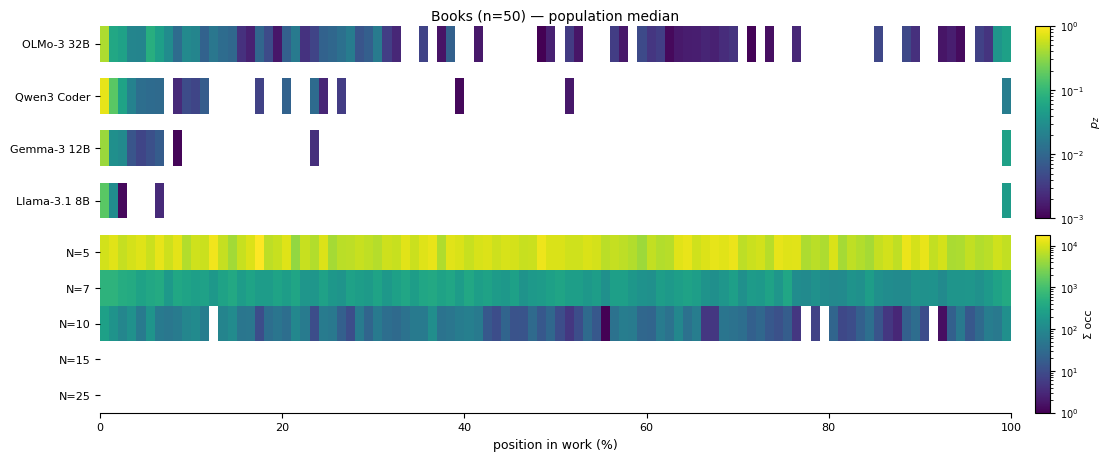

In [44]:
pop_books = compute_population_panels(MEM_DFS, BOOK_IDS_POP, agg="median")

fig = plt.figure(figsize=(11, 4.5), constrained_layout=True)
gs = GridSpec(1, 1, figure=fig)
render_population_panel(
    fig, gs[0, 0], pop_books,
    title=f"Books (n={pop_books['n_items']}) — population median",
)
plt.show()

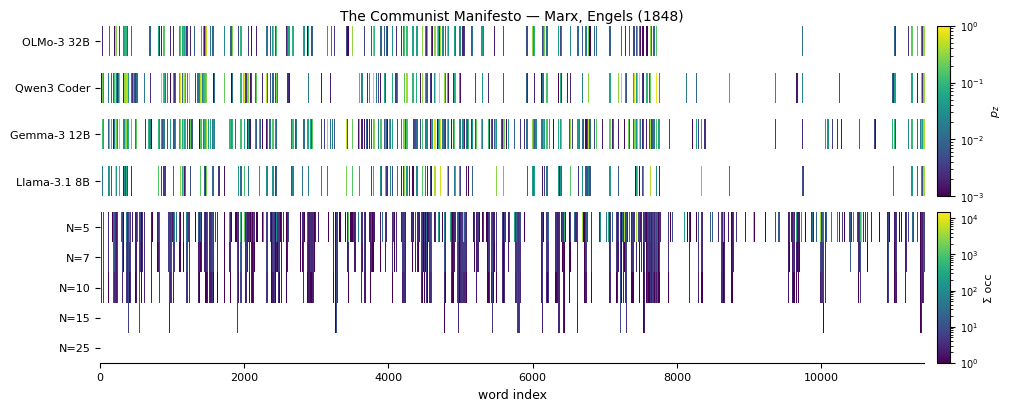

In [50]:
COMMMUNIST_MANIFESTO = "6d6fee158775445198e2a7e724debd4f87bb1986"

fig = plt.figure(figsize=(10, 4.0), constrained_layout=True)
gs = GridSpec(1, 1, figure=fig)
render_song_panel(fig, gs[0, 0], COMMMUNIST_MANIFESTO, MEM_DFS)
plt.show()

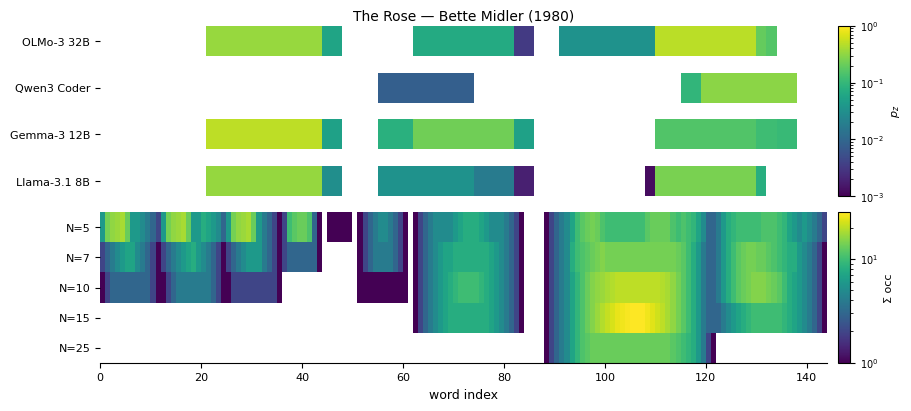

In [18]:
ID = "b45bff13d737ccbdeb45cb2069bd5946b176bc25"

fig = plt.figure(figsize=(9, 4.0), constrained_layout=True)
gs = GridSpec(1, 1, figure=fig)
render_song_panel(fig, gs[0, 0], ID, MEM_DFS)
plt.show()

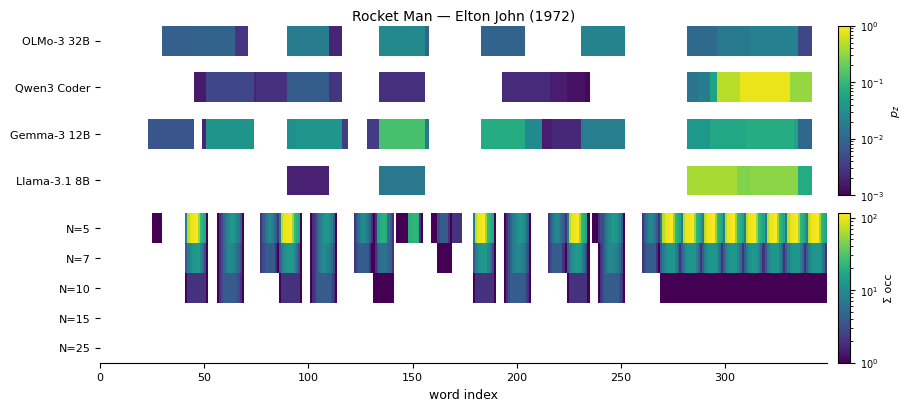

In [47]:
ID = "a87b72cffa16896bee066670cc217a7549558bc9"

fig = plt.figure(figsize=(9, 4.0), constrained_layout=True)
gs = GridSpec(1, 1, figure=fig)
render_song_panel(fig, gs[0, 0], ID, MEM_DFS)
plt.show()

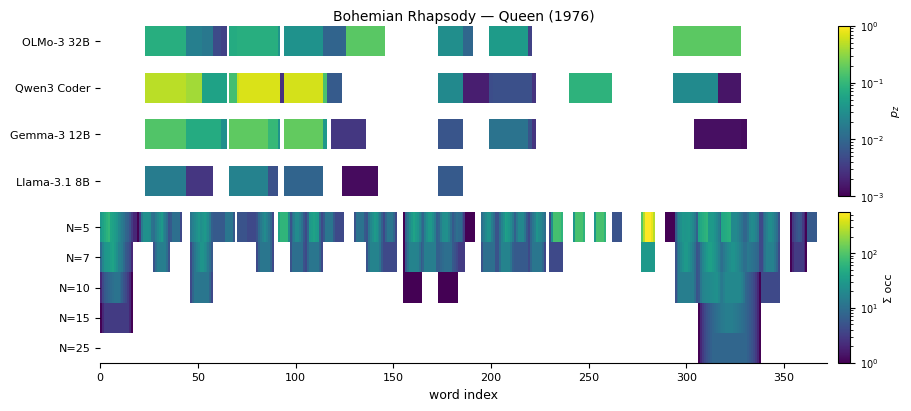

In [20]:
ID = "218b580a8a7e5299442efa9d74d1ccc6cc379b42"

fig = plt.figure(figsize=(9, 4.0), constrained_layout=True)
gs = GridSpec(1, 1, figure=fig)
render_song_panel(fig, gs[0, 0], ID, MEM_DFS)
plt.show()

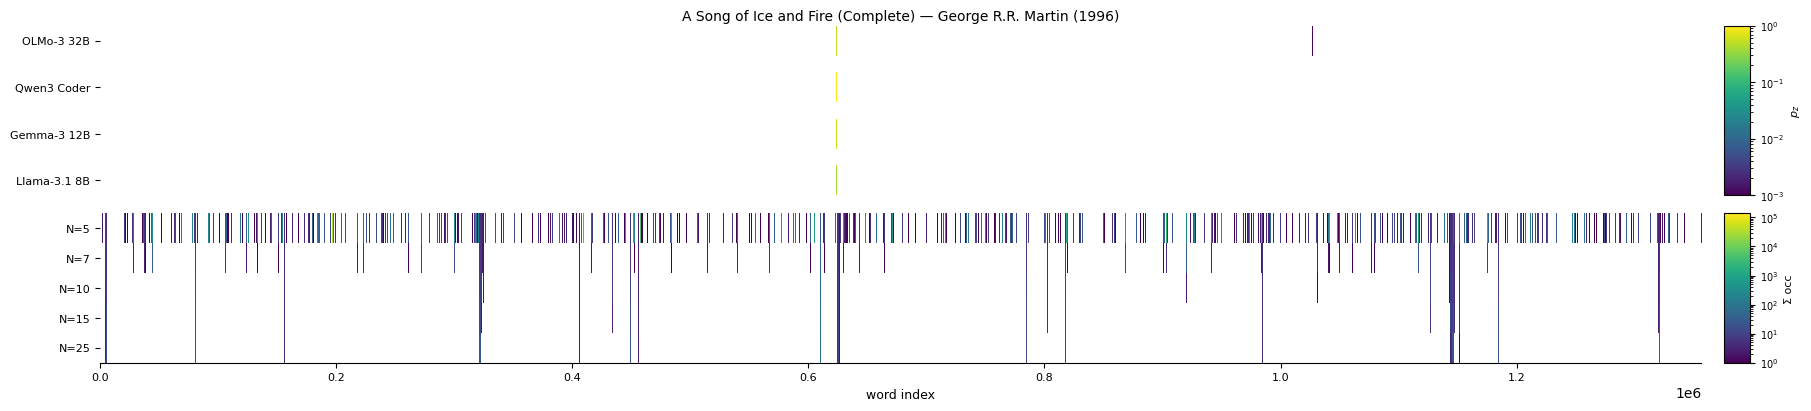

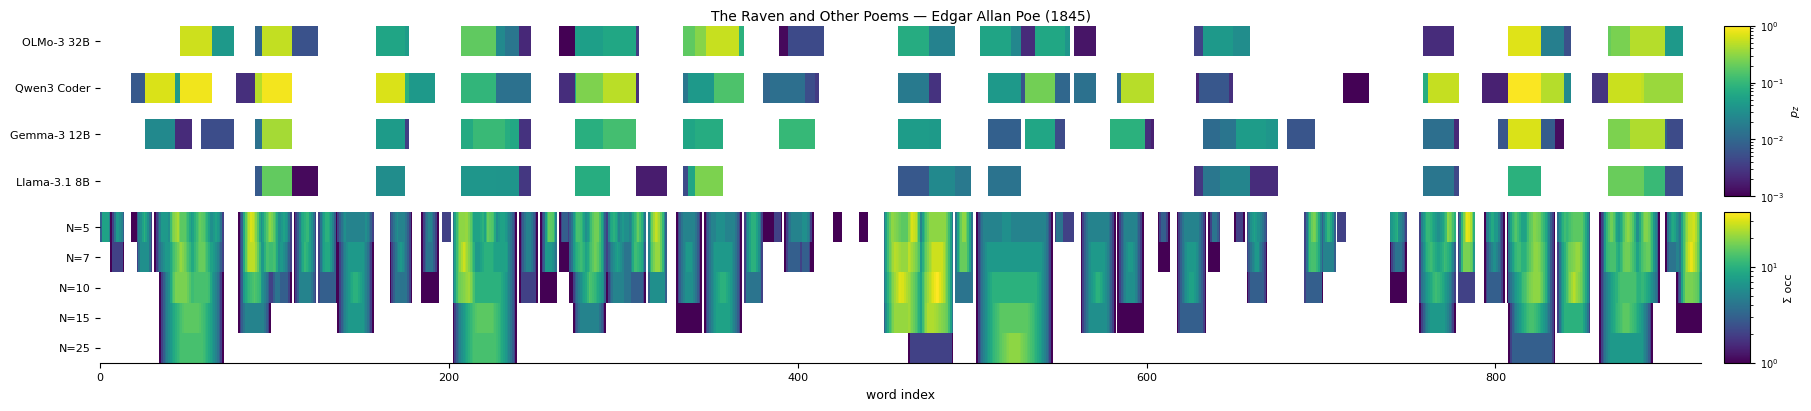

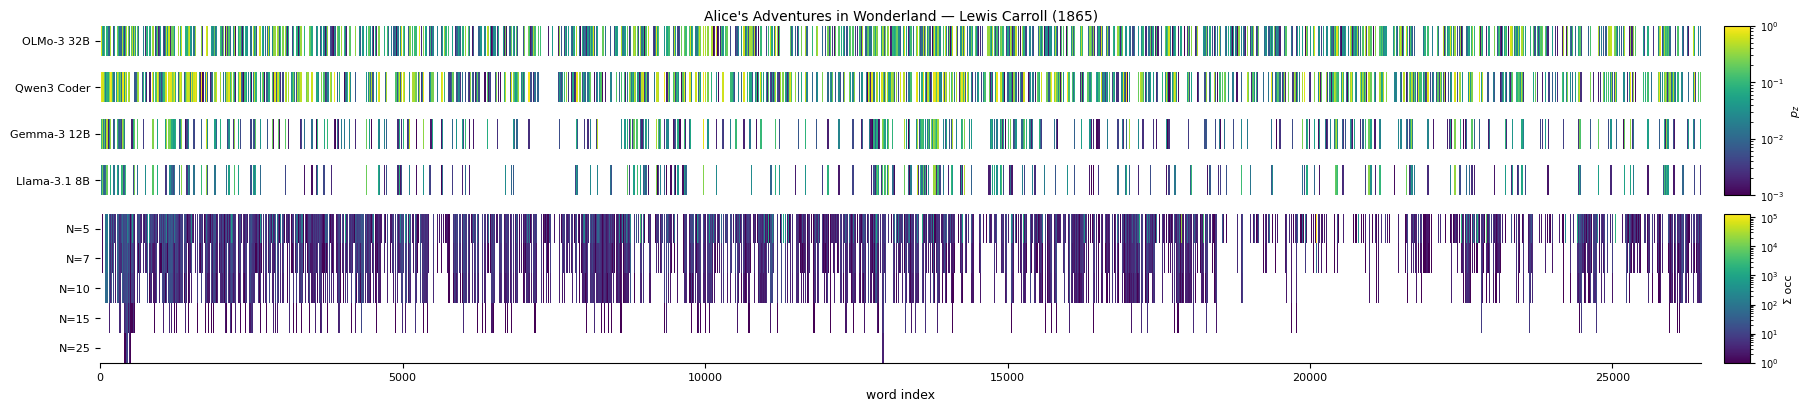

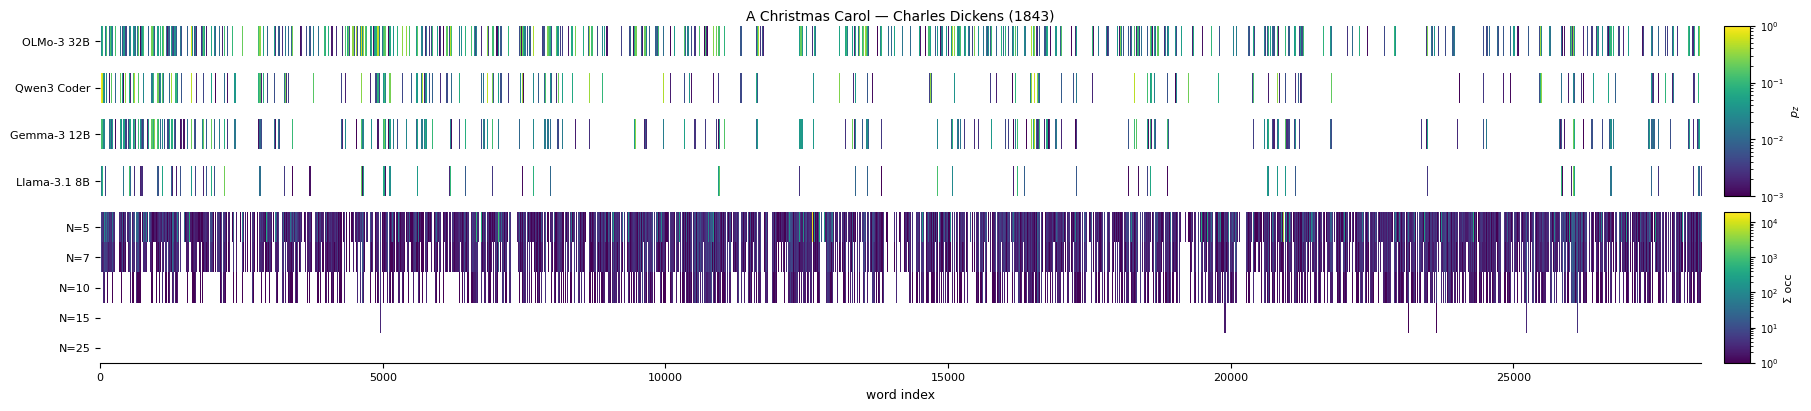

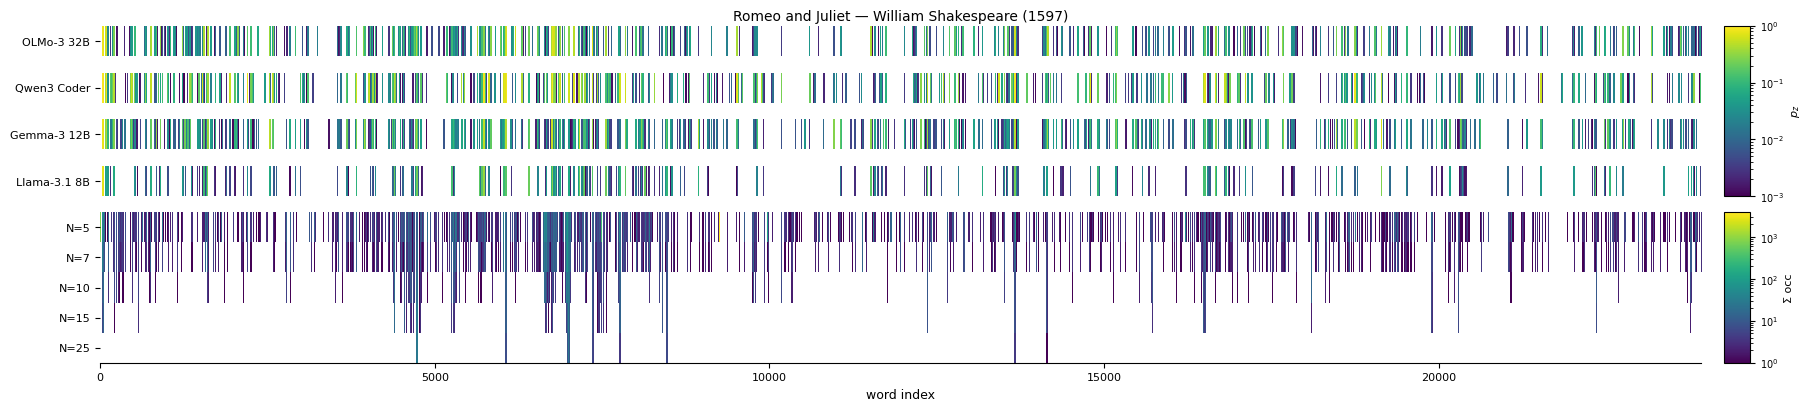

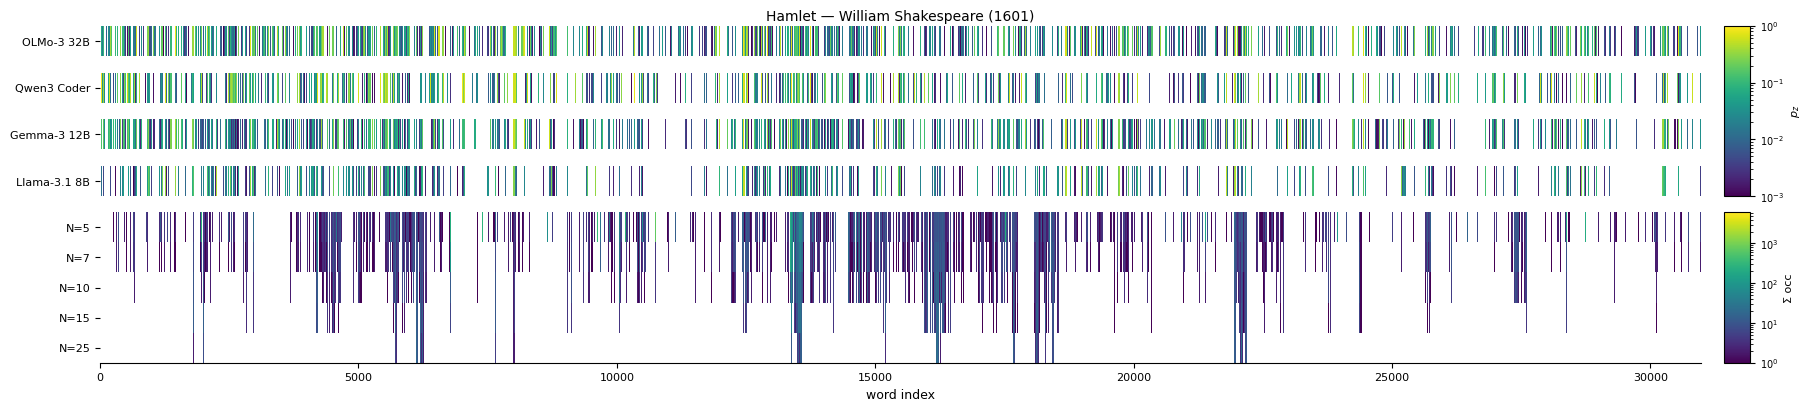

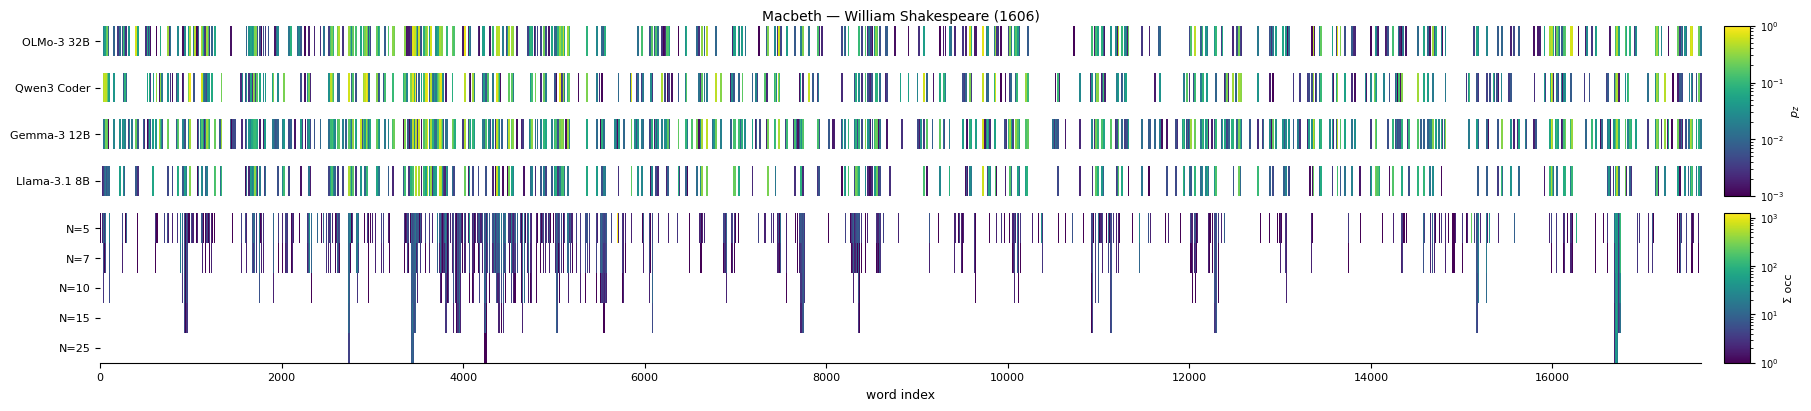

In [27]:
BOOK_IDS = ["731bc81c4a7cd705342bb30f8b6d9f4a5d658d04",
    "b512081c5506637bb0adfe60256e42f493f6a504", "90b8c3c6ed24c0db985e2cc88dbda1512a7a5217",
"cd55efd233c665203f261008c29e2c90d2681bd3",
"cbc637fca788f63f2cb28ec35af60482bd09c638",
"b60cbf31cc36425bb4b567860ea2bf78c173a069",
"c28fd9969e20a1add4e3a4d7a3674c990df75e16",]

for book_id in BOOK_IDS:
    fig = plt.figure(figsize=(18, 4.0), constrained_layout=True)
    gs = GridSpec(1, 1, figure=fig)
    render_song_panel(fig, gs[0, 0], book_id, MEM_DFS)
    plt.show()